# Demonstration of Non-linear Mixing with MUDBENCS Inorganic Geochemistry Data
This notebook accesses a .csv file from a data repository that emanated from an NSF-funded expedition and research project on the French Guiana mudbanks. Of interest in this exercise is the inorganic geochemistry data which were measured at a lower frequency than the organic geochemistry data. Still, ratios can be calculated and mixtures can be analyzed. Here we will determine if there is a mixture from drainage basins on different part of the S. American continent. 

In [1]:
#Import packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

#Load data into a dataframe:
df = pd.read_csv('../MUDBENCS_MC_data_repository.csv')
print(df.columns)


Index(['Unnamed: 0', 'sample_ID', 'mass_(mg)', 'd15N', 'd13C', 'pct_N',
       'pct_C', 'micromols_N', 'micromols_C', 'Fm', 'Si_wt_pct', 'Al_wt_pct',
       'Ti_wt_pct', 'Fe_wt_pct', 'Mn_wt_pct', 'Ca_wt_pct', 'Mg_wt_pct',
       'Na_wt_pct', 'K_wt_pct', 'Ba_microg/g', 'Cr_microg/g', 'Sc_microg/g',
       'Sr_microg/g', 'V_microg/g', 'Y_microg/g', 'Zn_microg/g', 'Zr_microg/g',
       'pct_clay', 'pct_silt', 'pct_vfn', 'pct_fine', 'pct_med', 'pct_crs',
       'pct_vcrs', 'd10', 'd50', 'd90', 'mean', 'sorting', 'skewness',
       'kurtosis', 'mass (mg)(N)', 'd15N_(N)', 'pct_C_(N)', 'C:N (mass)',
       'flags', 'top_depth', 'bottom_depth', 'core', 'pct_CaCO3',
       'C_pct_corrected', 'C_N_(mass)', 'C_N_(mass_corrected)', 'latitude',
       'longitude', 'station_number', 'station_name', 'on_station_time',
       'off_station_time'],
      dtype='object')


## Linear and Nonlinear Mixtures

We use the table 11.1 in Janousek et al., Ch. 11, to study binary plot types using element:element ratios. This table outlines the different relationships between coefficients in the hyperbolic relationship:

$Ax_m + Bx_my_m + Cy_m +D = 0$

...which can be further depicted as:

$y_m = - \frac{(Ax_m + D)}{(Bx_m + C)}$

Table 11.1 summarizes those coefficients in different binary plots as follows:

| Binary Plot Type | x | y | Coefficients | Straight when... |
| ---- | -- | -- | -- | ----|
| *ratio-ratio* | *v/b* | *u/a* | *A = b1u2-b2u1, B = a1b2 - a2b1, C = a2v1-a1v2, D = u1v2-u2v1* | *a1/a2 = b1/b2* |
| ratio-ratio (common denominator) | v/a | u/a | A = a1u2-a2u1, B = 0, C = a2v1-a1v2, D = u1v2-u2v1 | Always! |
| element-ratio | v | u/a | A = u2-u1, B = a1-a2, C = a2v1-a1v2, D = u1v2-u2v1 | a1=a2 |
| element-ratio (same element on both axes) | a | u/a | A = u2-u1,, B = a1-a2, C = 0, D = a2u1-a1u2 | a1 = a2 |
| two elements | v | u | A = u2-u1, B = 0, C = v1-v2, D = u1v2-u2v1 | Always! |


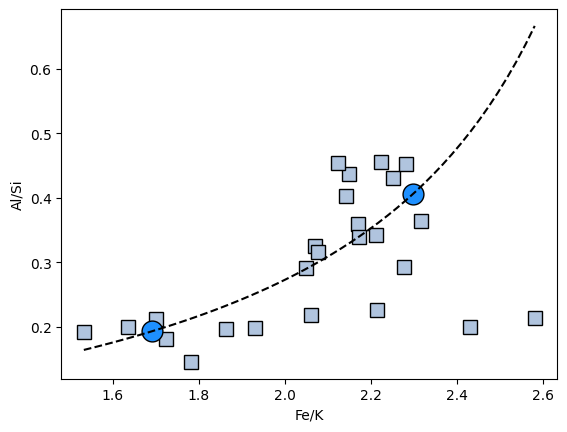

In [ ]:
#Make a ratio-ratio plot:

v = 'Fe_wt_pct'
b = 'K_wt_pct'
u = 'Al_wt_pct'
a = 'Si_wt_pct'

x = df[v]/df[b]
y = df[u]/df[a]

fig, ax = plt.subplots(nrows=1, ncols=1)
ax.plot(x, y, marker='s', markersize=10, mfc='lightsteelblue', mec='k', linestyle='')
ax.set(xlabel=v.split('_')[0]+'/'+b.split('_')[0], ylabel=u.split('_')[0]+'/'+a.split('_')[0])

#Define the endmembers of the mixing model. Use the closest site to the Amazon and the closest
#site to the Maroni and take the average of each. 

Amaz = '04MC'   #-endmember 1 is the Amazon
Maro = '18MC'   #-endmember 2 is the Maroni

v1 = df[v].loc[df['sample_ID'].str.contains(Amaz)].mean()
v2 = df[v].loc[df['sample_ID'].str.contains(Maro)].mean()
b1 = df[b].loc[df['sample_ID'].str.contains(Amaz)].mean()
b2 = df[b].loc[df['sample_ID'].str.contains(Maro)].mean()
u1 = df[u].loc[df['sample_ID'].str.contains(Amaz)].mean()
u2 = df[u].loc[df['sample_ID'].str.contains(Maro)].mean()
a1 = df[a].loc[df['sample_ID'].str.contains(Amaz)].mean()
a2 = df[a].loc[df['sample_ID'].str.contains(Maro)].mean()

#Plot endmembers:

ax.plot(v1/b1, u1/a1, marker='^', markersize=15, mfc='dodgerblue', mec='k', linestyle='')
ax.plot(v2/b2, u2/a2, marker='o', markersize=15, mfc='dodgerblue', mec='k', linestyle='')


#Calculate and plot the model:
A = b1*u2-b2*u1
B = a1*b2-a2*b1
C = a2*v1-a1*v2
D = u1*v2-u2*v1

x_m = np.linspace(min(x), max(x), 50)
y_m = -(A*x_m + D)/(B*x_m + C)

ax.plot(x_m, y_m, linestyle='--', color='k')



## Ratio-Ratio plot results

The hyperbolic mixing model runs through the end members, however there is a deviation between the data and the model at the high end of Fe/K. This may be representative of a third endmember evident in high Fe/K and low Al/Si. Despite the complexity of nonlinear mixing models, they still depend on the assumption of only two endmembers. 

### Next plot: Ratio-Ratio with common denominator:

| Binary Plot Type | x | y | Coefficients | Straight when... |
| ---- | -- | -- | -- | ----|
| ratio-ratio | v/b | u/a | A = b1u2-b2u1, B = a1b2 - a2b1, C = a2v1-a1v2, D = u1v2-u2v1 | a1/a2 = b1/b2 |
| *ratio-ratio (common denominator)* | *v/a* | *u/a* | *A = a1u2-a2u1, B = 0, C = a2v1-a1v2, D = u1v2-u2v1* | *Always!* |
| element-ratio | v | u/a | A = u2-u1, B = a1-a2, C = a2v1-a1v2, D = u1v2-u2v1 | a1=a2 |
| element-ratio (same element on both axes) | a | u/a | A = u2-u1,, B = a1-a2, C = 0, D = a2u1-a1u2 | a1 = a2 |
| two elements | v | u | A = u2-u1, B = 0, C = v1-v2, D = u1v2-u2v1 | Always! |


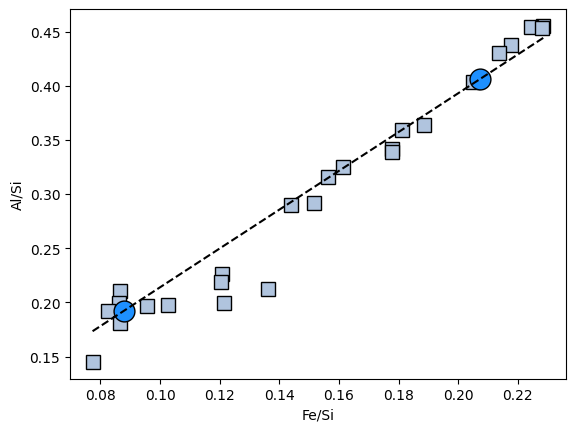

In [ ]:
#Make a ratio:ratio plot with a common denominator

#Use the same values of u, v, b, and a from above, but the ratios change. 

x = df[v]/df[a]
y = df[u]/df[a]

fig, ax = plt.subplots(nrows=1, ncols=1)
ax.plot(x, y, marker='s', markersize=10, mfc='lightsteelblue', mec='k', linestyle='')
ax.set(xlabel=v.split('_')[0]+'/'+a.split('_')[0], ylabel=u.split('_')[0]+'/'+a.split('_')[0])

#Define the endmembers of the mixing model. Use the closest site to the Amazon and the closest
#site to the Maroni and take the average of each. 

Amaz = '04MC'   #-endmember 1 is the Amazon
Maro = '18MC'   #-endmember 2 is the Maroni

v1 = df[v].loc[df['sample_ID'].str.contains(Amaz)].mean()
v2 = df[v].loc[df['sample_ID'].str.contains(Maro)].mean()
u1 = df[u].loc[df['sample_ID'].str.contains(Amaz)].mean()
u2 = df[u].loc[df['sample_ID'].str.contains(Maro)].mean()
a1 = df[a].loc[df['sample_ID'].str.contains(Amaz)].mean()
a2 = df[a].loc[df['sample_ID'].str.contains(Maro)].mean()

#Plot endmembers:

ax.plot(v1/a1, u1/a1, marker='^', markersize=15, mfc='dodgerblue', mec='k', linestyle='')
ax.plot(v2/a2, u2/a2, marker='o', markersize=15, mfc='dodgerblue', mec='k', linestyle='')

#Calculate and plot the model:
A = a1*u2-a2*u1
B = 0
C = a2*v1-a1*v2
D = u1*v2-u2*v1

x_m = np.linspace(min(x), max(x), 50)
y_m = -(A*x_m + D)/(B*x_m + C)

ax.plot(x_m, y_m, linestyle='--', color='k')


## Ratio - Ratio plot with common denominator results
This plot shows a nice mixture line that is straight, but there are still some points that fall off of the line. Some of the lowest Al/Si points, which were likely the ones that fell off the line in the ratio-ratio plot above, are lower than the mixing line and probably related points. Again, the suggestion would be that this system is not a perfect 2-member mixture, which may be useful information. 

### Next plot: Ratio vs. element
| Binary Plot Type | x | y | Coefficients | Straight when... |
| ---- | -- | -- | -- | ----|
| ratio-ratio | v/b | u/a | A = b1u2-b2u1, B = a1b2 - a2b1, C = a2v1-a1v2, D = u1v2-u2v1 | a1/a2 = b1/b2 |
| ratio-ratio (common denominator) | v/a | u/a | A = a1u2-a2u1, B = 0, C = a2v1-a1v2, D = u1v2-u2v1 | Always! |
| *element-ratio* | *v* | *u/a* | *A = u2-u1, B = a1-a2, C = a2v1-a1v2, D = u1v2-u2v1* | *a1=a2* |
| element-ratio (same element on both axes) | a | u/a | A = u2-u1,, B = a1-a2, C = 0, D = a2u1-a1u2 | a1 = a2 |
| two elements | v | u | A = u2-u1, B = 0, C = v1-v2, D = u1v2-u2v1 | Always! |


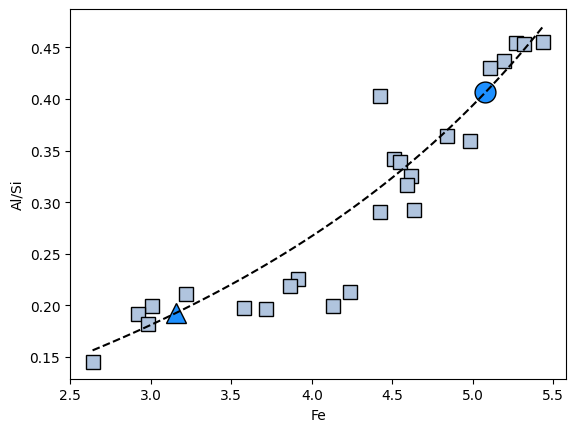

In [30]:
#Make an element:ratio plot 

#Use the same values of u, v, b, and a from above, but the ratios change. 

x = df[v]
y = df[u]/df[a]

fig, ax = plt.subplots(nrows=1, ncols=1)
ax.plot(x, y, marker='s', markersize=10, mfc='lightsteelblue', mec='k', linestyle='')
ax.set(xlabel=v.split('_')[0], ylabel=u.split('_')[0]+'/'+a.split('_')[0])

#Define the endmembers of the mixing model. Use the closest site to the Amazon and the closest
#site to the Maroni and take the average of each. 

Amaz = '04MC'   #-endmember 1 is the Amazon
Maro = '18MC'   #-endmember 2 is the Maroni

v1 = df[v].loc[df['sample_ID'].str.contains(Amaz)].mean()
v2 = df[v].loc[df['sample_ID'].str.contains(Maro)].mean()
u1 = df[u].loc[df['sample_ID'].str.contains(Amaz)].mean()
u2 = df[u].loc[df['sample_ID'].str.contains(Maro)].mean()
a1 = df[a].loc[df['sample_ID'].str.contains(Amaz)].mean()
a2 = df[a].loc[df['sample_ID'].str.contains(Maro)].mean()

#Plot endmembers:

ax.plot(v1, u1/a1, marker='^', markersize=15, mfc='dodgerblue', mec='k', linestyle='')
ax.plot(v2, u2/a2, marker='o', markersize=15, mfc='dodgerblue', mec='k', linestyle='')

#Calculate and plot the model:
A = u2-u1
B = a1-a2
C = a2*v1-a1*v2
D = u1*v2-u2*v1

x_m = np.linspace(min(x), max(x), 50)
y_m = -(A*x_m + D)/(B*x_m + C)

ax.plot(x_m, y_m, linestyle='--', color='k')




## Ratio vs. element plot results:

Here the model follows the data generally, but it seems that at the mid-range of Fe concentration more points fall off the line. In fact, one could say that the mixing model performs worse when we just look at iron without ratioing it to another weathering element. 

### Next plot: Ratio vs. element with same element in ratio

| Binary Plot Type | x | y | Coefficients | Straight when... |
| ---- | -- | -- | -- | ----|
| ratio-ratio | v/b | u/a | A = b1u2-b2u1, B = a1b2 - a2b1, C = a2v1-a1v2, D = u1v2-u2v1 | a1/a2 = b1/b2 |
| ratio-ratio (common denominator) | v/a | u/a | A = a1u2-a2u1, B = 0, C = a2v1-a1v2, D = u1v2-u2v1 | Always! |
| element-ratio | v | u/a | A = u2-u1, B = a1-a2, C = a2v1-a1v2, D = u1v2-u2v1 | a1=a2 |
| *element-ratio (same element on both axes)* | *a* | *u/a* | *A = u2-u1, B = a1-a2, C = 0, D = a2u1-a1u2* | *a1 = a2* |
| two elements | v | u | A = u2-u1, B = 0, C = v1-v2, D = u1v2-u2v1 | Always! |


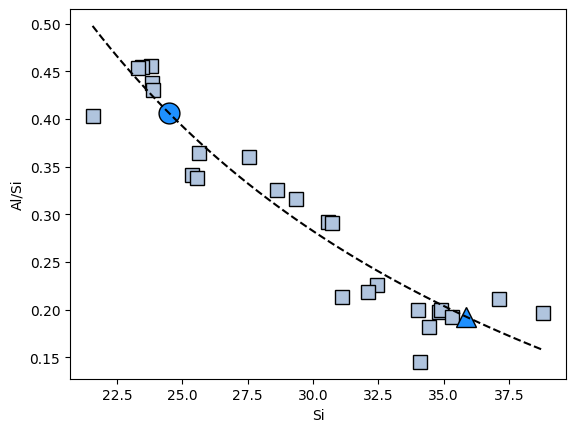

In [33]:
#Make an element:ratio plot with the same element in the ratio:

#Use the same values of u, v, b, and a from above, but the ratios change. 

x = df[a]
y = df[u]/df[a]

fig, ax = plt.subplots(nrows=1, ncols=1)
ax.plot(x, y, marker='s', markersize=10, mfc='lightsteelblue', mec='k', linestyle='')
ax.set(xlabel=a.split('_')[0], ylabel=u.split('_')[0]+'/'+a.split('_')[0])

#Define the endmembers of the mixing model. Use the closest site to the Amazon and the closest
#site to the Maroni and take the average of each. 

Amaz = '04MC'   #-endmember 1 is the Amazon
Maro = '18MC'   #-endmember 2 is the Maroni

u1 = df[u].loc[df['sample_ID'].str.contains(Amaz)].mean()
u2 = df[u].loc[df['sample_ID'].str.contains(Maro)].mean()
a1 = df[a].loc[df['sample_ID'].str.contains(Amaz)].mean()
a2 = df[a].loc[df['sample_ID'].str.contains(Maro)].mean()

#Plot endmembers:
ax.plot(a1, u1/a1, marker='^', markersize=15, mfc='dodgerblue', mec='k', linestyle='')
ax.plot(a2, u2/a2, marker='o', markersize=15, mfc='dodgerblue', mec='k', linestyle='')

#Calculate and plot the model:
A = u2-u1
B = a1-a2
C = 0
D = u1*a2-u2*a1

x_m = np.linspace(min(x), max(x), 50)
y_m = -(A*x_m + D)/(B*x_m + C)

ax.plot(x_m, y_m, linestyle='--', color='k')




## Ratio vs. element (with common element in ratio) results:

This model, once Fe and K are removed, performs very well. The mixture shows a strong progression from the Amazon to the Maroni endmember. As more Si is added to the mixture, the amount of Al becomes less important in the ratio Al/Si. Lower values of Al/Si are indicative of weathering in drier regions, but it is hard to think of anywhere in S. American as dry. In fact, the driest region in these two basins is likely the highlands of the Guyana shield where savannahs replace rain forests. This would be in the Maroni, and not the Amazon, however. Confounding! Because Fe/K is sensitive to mafic input and Andes topography, removing it completely may yield a better indicator of weathering. 

Next plot: Two elements

| Binary Plot Type | x | y | Coefficients | Straight when... |
| ---- | -- | -- | -- | ----|
| ratio-ratio | v/b | u/a | A = b1u2-b2u1, B = a1b2 - a2b1, C = a2v1-a1v2, D = u1v2-u2v1 | a1/a2 = b1/b2 |
| ratio-ratio (common denominator) | v/a | u/a | A = a1u2-a2u1, B = 0, C = a2v1-a1v2, D = u1v2-u2v1 | Always! |
| element-ratio | v | u/a | A = u2-u1, B = a1-a2, C = a2v1-a1v2, D = u1v2-u2v1 | a1=a2 |
| element-ratio (same element on both axes) | a | u/a | A = u2-u1,, B = a1-a2, C = 0, D = a2u1-a1u2 | a1 = a2 |
| *two elements* | *v* | *u* | *A = u2-u1, B = 0, C = v1-v2, D = u1v2-u2v1* | *Always!* |


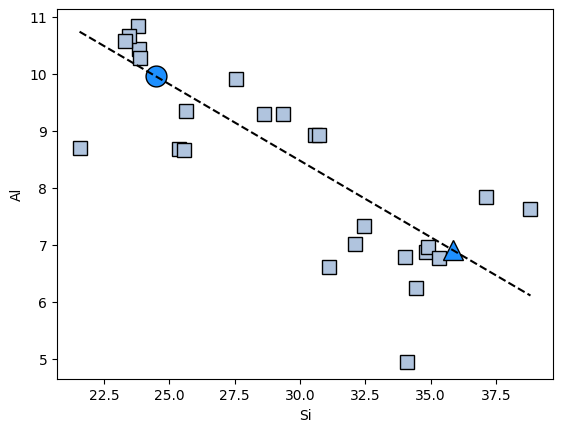

In [34]:
#Make an element:ratio plot with the same element in the ratio:

#Use the same values of u, v, b, and a from above, but the ratios change. 

x = df[a]
y = df[u]

fig, ax = plt.subplots(nrows=1, ncols=1)
ax.plot(x, y, marker='s', markersize=10, mfc='lightsteelblue', mec='k', linestyle='')
ax.set(xlabel=a.split('_')[0], ylabel=u.split('_')[0])

#Define the endmembers of the mixing model. Use the closest site to the Amazon and the closest
#site to the Maroni and take the average of each. 

Amaz = '04MC'   #-endmember 1 is the Amazon
Maro = '18MC'   #-endmember 2 is the Maroni

u1 = df[u].loc[df['sample_ID'].str.contains(Amaz)].mean()
u2 = df[u].loc[df['sample_ID'].str.contains(Maro)].mean()
a1 = df[a].loc[df['sample_ID'].str.contains(Amaz)].mean()
a2 = df[a].loc[df['sample_ID'].str.contains(Maro)].mean()

#Plot endmembers:
ax.plot(a1, u1, marker='^', markersize=15, mfc='dodgerblue', mec='k', linestyle='')
ax.plot(a2, u2, marker='o', markersize=15, mfc='dodgerblue', mec='k', linestyle='')

#Calculate and plot the model:
A = u2-u1
B = 0
C = a1-a2
D = u1*a2-u2*a1

x_m = np.linspace(min(x), max(x), 50)
y_m = -(A*x_m + D)/(B*x_m + C)

ax.plot(x_m, y_m, linestyle='--', color='k')

## Element vs. Element Results

This linear mixture seems to follow the model, but with a lot of noise. This is the simplest of all of our mixing models, and it shows that sometimes elemental concentration is more complex. Obviously, ratioing the elements in cases above produced some better fits, but this element:element plot may be easier to conceptualize and rationalize. This is a case, however, with these data, where a simple model may be too simple; it incorporates a good bit of noise limiting its statistical utility. 

### Questions to ponder

This exercise leads to several questions to ponder. 
1. What about other elements and ratios? What can they tell us?
2. Endmembers - we used averages from opposite sites, which, in a way, guarantees success of these models. What if we used actual end members from the Andes (Amazon) and the Guyanas Shield (Maroni)? How might that effect the ability of these models to fit the data? 
3. Is there a marine endmember? What minerals and what source of that mineral may cause a marine endmember? 